# Análise Exploratória de Dados — Customer Churn

Este notebook realiza a investigação inicial do conjunto de dados de clientes de uma empresa de telecomunicações. O objetivo é compreender a estrutura e a qualidade dos dados, identificar possíveis riscos para a modelagem e analisar a distribuição da variável alvo de churn.

Nesta etapa, os problemas encontrados serão diagnosticados e documentados. A remoção de colunas, a imputação de valores ausentes e as demais transformações serão realizadas posteriormente, na etapa de preparação dos dados.

## 1. Importações

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

## 2. Investigação inicial do dataset

### 2.1. Leitura do dataset bruto

O arquivo original é carregado em formato Excel. Inicialmente, são verificadas as planilhas disponíveis e realizada a leitura da planilha que contém os dados de churn.

In [2]:
xlsx_path = Path("../data/raw/Telco_customer_churn.xlsx")

excel = pd.ExcelFile(xlsx_path)
excel.sheet_names

['Telco_Churn']

In [3]:
df = pd.read_excel(xlsx_path, sheet_name="Telco_Churn")

display(df.head())

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [4]:
print(f"Linhas: {df.shape[0]:,}")
print(f"Colunas: {df.shape[1]}")

df.info()

Linhas: 7,043
Colunas: 33
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet 

### 2.2. Conversão para Parquet

A variável `Total Charges` é convertida para o tipo numérico. Valores que não puderem ser convertidos, como espaços em branco existentes no arquivo original, serão representados como `NaN`. Esses casos serão investigados na seção de qualidade dos dados.

O dataset é salvo em Parquet para tornar as próximas leituras mais rápidas e preservar os tipos das colunas.

In [5]:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce",
)

processed_path = Path("../data/processed/dataset.parquet")
processed_path.parent.mkdir(parents=True, exist_ok=True)

df.to_parquet(processed_path, index=False)

In [6]:
df = pd.read_parquet(processed_path)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

## 3. Visão geral do dataset

### 3.1. Dimensões do dataset

In [7]:
n_rows, n_cols = df.shape

print(f"Número de registros: {n_rows:,}")
print(f"Número de variáveis: {n_cols}")

Número de registros: 7,043
Número de variáveis: 33


O dataset possui **7.043 registros e 33 variáveis**, representando as informações disponíveis para a análise e para a posterior construção dos modelos de Machine Learning.

### 3.2. Visualização inicial

Além dos primeiros registros, é apresentada uma amostra aleatória. Isso evita formar uma impressão do dataset baseada somente na ordenação original das linhas.

In [8]:
display(df.head())
display(df.sample(5, random_state=42))

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
185,2189-WWOEW,1,United States,California,Keene,93531,"35.214982, -118.59049",35.214982,-118.590490,Female,...,Month-to-month,Yes,Bank transfer (automatic),85.9,1269.55,Yes,1,96,3579,Don't know
2715,2446-ZKVAF,1,United States,California,Stockton,95207,"38.002125, -121.324979",38.002125,-121.324979,Male,...,Month-to-month,No,Credit card (automatic),56.8,1074.65,No,0,59,5558,NaN
3825,4986-MXSFP,1,United States,California,San Leandro,94579,"37.687264, -122.15728",37.687264,-122.157280,Female,...,Month-to-month,Yes,Mailed check,20.0,40.90,No,0,39,2237,NaN
1807,5868-YWPDW,1,United States,California,Sherman Oaks,91423,"34.146957, -118.432138",34.146957,-118.432138,Male,...,Month-to-month,Yes,Electronic check,84.2,519.15,Yes,1,72,5834,Limited range of services
132,9412-GHEEC,1,United States,California,Murrieta,92563,"33.581045, -117.14719",33.581045,-117.147190,Male,...,Month-to-month,No,Bank transfer (automatic),104.8,4131.95,Yes,1,88,3492,Service dissatisfaction


### 3.3. Variáveis disponíveis

In [9]:
df.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason']

### 3.4. Resumo estatístico inicial

O resumo numérico permite observar medidas de posição e dispersão. Já o resumo das variáveis categóricas mostra a quantidade de categorias, a categoria mais frequente e sua frequência.

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Count,7043.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Zip Code,7043.0,93521.964646,1865.794555,90001.000000,92102.000000,93552.000000,95351.000000,96161.000000
Latitude,7043.0,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,-119.798880,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Tenure Months,7043.0,32.371149,24.559481,0.000000,9.000000,29.000000,55.000000,72.000000
Monthly Charges,7043.0,64.761692,30.090047,18.250000,35.500000,70.350000,89.850000,118.750000
Total Charges,7032.0,2283.300441,2266.771362,18.800000,401.450000,1397.475000,3794.737500,8684.800000
Churn Value,7043.0,0.265370,0.441561,0.000000,0.000000,0.000000,1.000000,1.000000
Churn Score,7043.0,58.699418,21.525131,5.000000,40.000000,61.000000,75.000000,100.000000
CLTV,7043.0,4400.295755,1183.057152,2003.000000,3469.000000,4527.000000,5380.500000,6500.000000


In [11]:
df.describe(include=["object", "string"]).T

,count,unique,top,freq
CustomerID,7043,7043,3668-QPYBK,1
Country,7043,1,United States,7043
State,7043,1,California,7043
City,7043,1129,Los Angeles,305
Lat Long,7043,1652,"33.964131, -118.272783",5
Gender,7043,2,Male,3555
Senior Citizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,5416
Phone Service,7043,2,Yes,6361


## 4. Qualidade dos dados

Antes das análises estatísticas e da construção dos modelos, é necessário avaliar a qualidade dos dados. Nesta etapa são investigados os tipos das variáveis, valores ausentes, duplicidades, colunas constantes, possíveis redundâncias e riscos de vazamento da variável alvo.

### 4.1. Tipos das variáveis

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [13]:
types = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Valores únicos": df.nunique(dropna=False),
})

display(types)

,Tipo,Valores únicos
CustomerID,str,7043
Count,int64,1
Country,str,1
State,str,1
City,str,1129
Zip Code,int64,1652
Lat Long,str,1652
Latitude,float64,1652
Longitude,float64,1651
Gender,str,2


O tipo técnico utilizado pelo Pandas nem sempre representa o papel conceitual da variável. Por exemplo, `Zip Code` é armazenada como número inteiro, mas representa um código geográfico, enquanto `Churn Value` é numérica e binária. Essa distinção será considerada no preprocessing.

### 4.2. Valores ausentes

In [14]:
missing = pd.DataFrame({
    "Quantidade": df.isna().sum(),
    "Percentual (%)": (df.isna().mean() * 100).round(2),
})

display(missing.sort_values("Quantidade", ascending=False))

,Quantidade,Percentual (%)
Churn Reason,5174,73.46
Total Charges,11,0.16
CustomerID,0,0.00
Count,0,0.00
Country,0,0.00
Zip Code,0,0.00
Lat Long,0,0.00
State,0,0.00
City,0,0.00
Gender,0,0.00


#### 4.2.1. Investigação de `Total Charges`

In [15]:
total_charges_missing = df.loc[
    df["Total Charges"].isna(),
    [
        "CustomerID",
        "Tenure Months",
        "Monthly Charges",
        "Total Charges",
        "Churn Label",
    ],
]

display(total_charges_missing)

print(
    "Valores de Tenure Months entre os registros com Total Charges ausente:"
)
display(total_charges_missing["Tenure Months"].value_counts(dropna=False))

,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,NaN,No
2438,3115-CZMZD,0,20.25,NaN,No
2568,5709-LVOEQ,0,80.85,NaN,No
2667,4367-NUYAO,0,25.75,NaN,No
2856,1371-DWPAZ,0,56.05,NaN,No
4331,7644-OMVMY,0,19.85,NaN,No
4687,3213-VVOLG,0,25.35,NaN,No
5104,2520-SGTTA,0,20.00,NaN,No
5719,2923-ARZLG,0,19.70,NaN,No
6772,4075-WKNIU,0,73.35,NaN,No


Valores de Tenure Months entre os registros com Total Charges ausente:


Tenure Months
0    11
Name: count, dtype: int64

In [16]:
all_missing_total_charges_have_zero_tenure = (
    total_charges_missing["Tenure Months"].eq(0).all()
)

print(
    "Todos os registros com Total Charges ausente possuem "
    f"Tenure Months = 0? {all_missing_total_charges_have_zero_tenure}"
)

Todos os registros com Total Charges ausente possuem Tenure Months = 0? True


Foram identificados **11 valores ausentes em `Total Charges`**, equivalentes a **0,16%** do dataset. A verificação acima permite confirmar se todos pertencem a clientes com `Tenure Months = 0`.

Caso a condição seja verdadeira, os ausentes possuem uma explicação de negócio: são clientes recém-ingressos, sem cobrança total acumulada. A estratégia de tratamento deverá ser definida no preprocessing após validar o significado da cobrança. Não será aplicada imputação por média ou mediana nesta etapa, pois isso desconsideraria a origem do valor ausente.

#### 4.2.2. Investigação de `Churn Reason`

In [17]:
churn_reason_missing_by_target = pd.crosstab(
    df["Churn Label"],
    df["Churn Reason"].isna(),
    rownames=["Churn Label"],
    colnames=["Churn Reason ausente"],
    margins=True,
)

display(churn_reason_missing_by_target)

Churn Reason ausente,False,True,All
Churn Label,,,
No,0,5174,5174
Yes,1869,0,1869
All,1869,5174,7043


A variável `Churn Reason` possui **5.174 valores ausentes (73,46%)**. Essa quantidade coincide com o número de clientes que não apresentaram churn, indicando uma **ausência estrutural**, e não uma falha aleatória de coleta: o motivo só é aplicável quando o cliente deixa a empresa.

Além disso, essa informação somente é conhecida após a ocorrência do churn. Por isso, `Churn Reason` não deverá ser imputada nem utilizada como variável preditora.

### 4.3. Registros duplicados

In [18]:
print(f"Duplicatas completas: {df.duplicated().sum()}")
print(
    "CustomerIDs duplicados:",
    df["CustomerID"].duplicated().sum(),
)
print(f"CustomerIDs únicos: {df['CustomerID'].nunique():,}")
print(f"Total de registros: {len(df):,}")

Duplicatas completas: 0
CustomerIDs duplicados: 0
CustomerIDs únicos: 7,043
Total de registros: 7,043


Não foram identificados registros completamente duplicados. Também não existem identificadores repetidos: há 7.043 valores únicos de `CustomerID` para 7.043 registros. Portanto, cada linha representa um cliente diferente.

### 4.4. Colunas constantes

In [19]:
constant_columns = [
    column
    for column in df.columns
    if df[column].nunique(dropna=False) == 1
]

constant_columns

['Count', 'Country', 'State']

As variáveis `Count`, `Country` e `State` possuem um único valor em todo o dataset. Como não apresentam variabilidade, não oferecem informação discriminativa para a previsão e poderão ser removidas durante o preprocessing.

### 4.5. Identificadores, redundâncias e alta cardinalidade

In [20]:
high_cardinality = (
    types
    .assign(
        **{
            "Percentual único (%)": (
                types["Valores únicos"] / len(df) * 100
            ).round(2)
        }
    )
    .sort_values("Valores únicos", ascending=False)
)

display(high_cardinality.head(10))

,Tipo,Valores únicos,Percentual único (%)
CustomerID,str,7043,100.00
Total Charges,float64,6531,92.73
CLTV,int64,3438,48.81
Lat Long,str,1652,23.46
Latitude,float64,1652,23.46
Zip Code,int64,1652,23.46
Longitude,float64,1651,23.44
Monthly Charges,float64,1585,22.50
City,str,1129,16.03
Churn Score,int64,85,1.21


A variável `CustomerID` é um identificador único e deve ser mantida apenas para rastreabilidade, não como variável preditora.

As variáveis `City` e `Zip Code` apresentam alta cardinalidade. Já `Lat Long` é uma representação textual das coordenadas também presentes em `Latitude` e `Longitude`, criando redundância. Antes da modelagem, será necessário decidir quais informações geográficas são realmente úteis e evitar utilizar simultaneamente representações equivalentes.

### 4.6. Variáveis com risco de vazamento do target

In [21]:
target_consistency = pd.crosstab(
    df["Churn Label"],
    df["Churn Value"],
    margins=True,
)

display(target_consistency)

Churn Value,0,1,All
Churn Label,,,
No,5174,0,5174
Yes,0,1869,1869
All,5174,1869,7043


A tabela confirma que `Churn Label` e `Churn Value` são duas representações da mesma variável: `No = 0` e `Yes = 1`. Portanto, apenas uma delas deve ser escolhida como target.

Para este projeto, será utilizado **`Churn Label` como único target**, caracterizando um problema de classificação binária. As seguintes colunas não deverão ser utilizadas como features:

- `Churn Value`: cópia numérica exata do target;
- `Churn Score`: pontuação de churn previamente calculada;
- `Churn Reason`: informação conhecida somente depois que o churn ocorre.

Utilizá-las permitiria que o modelo acessasse direta ou indiretamente a resposta que deveria prever, causando **vazamento de dados** e resultados artificialmente otimistas.

A variável `CLTV` também exige validação: ela só poderá ser usada se estiver disponível no momento da previsão e se for calculada exclusivamente com informações anteriores a esse momento.

In [22]:
target_column = "Churn Label"

identifier_columns = ["CustomerID"]
constant_columns = ["Count", "Country", "State"]
leakage_columns = ["Churn Value", "Churn Score", "Churn Reason"]
redundant_columns = ["Lat Long"]

print(f"Target: {target_column}")
print(f"Identificador: {identifier_columns}")
print(f"Colunas constantes: {constant_columns}")
print(f"Possível vazamento: {leakage_columns}")
print(f"Representação geográfica redundante: {redundant_columns}")

Target: Churn Label
Identificador: ['CustomerID']
Colunas constantes: ['Count', 'Country', 'State']
Possível vazamento: ['Churn Value', 'Churn Score', 'Churn Reason']
Representação geográfica redundante: ['Lat Long']


### 4.7. Resumo da qualidade

In [23]:
summary = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Únicos": df.nunique(),
    "Ausentes": df.isna().sum(),
    "Ausentes (%)": (df.isna().mean() * 100).round(2),
})

display(summary)

,Tipo,Únicos,Ausentes,Ausentes (%)
CustomerID,str,7043,0,0.00
Count,int64,1,0,0.00
Country,str,1,0,0.00
State,str,1,0,0.00
City,str,1129,0,0.00
Zip Code,int64,1652,0,0.00
Lat Long,str,1652,0,0.00
Latitude,float64,1652,0,0.00
Longitude,float64,1651,0,0.00
Gender,str,2,0,0.00


**Principais observações:**

- O dataset possui 7.043 registros e não apresenta linhas completamente duplicadas.
- `CustomerID` é único para cada observação e será mantido apenas como identificador.
- `Count`, `Country` e `State` são constantes e não oferecem poder discriminativo.
- Foram identificados 11 valores ausentes em `Total Charges`, aparentemente associados a clientes com tempo de permanência igual a zero. A hipótese deve ser confirmada pela saída da investigação antes da definição do tratamento.
- As ausências de `Churn Reason` são estruturais e correspondem aos clientes que não apresentaram churn.
- `Churn Value`, `Churn Score` e `Churn Reason` não deverão ser utilizadas como variáveis preditoras devido ao risco de vazamento do target.
- As variáveis geográficas apresentam redundância e algumas possuem alta cardinalidade, exigindo avaliação antes da modelagem.
- `CLTV` deverá ter sua disponibilidade temporal validada antes de ser utilizada como feature.
- Os tratamentos serão implementados posteriormente, preservando neste EDA a visão original do conjunto de dados.

## 5. Análise do target

A variável **`Churn Label`** será utilizada como único target do problema de Machine Learning. Ela indica se determinado cliente deixou ou não de utilizar os serviços da empresa:

- `No`: cliente permaneceu;
- `Yes`: cliente apresentou churn.

Antes de analisar a relação entre as demais características e o churn, é necessário avaliar a distribuição das classes.

### 5.1. Classes e distribuição

In [24]:
print("Classes:", df["Churn Label"].unique().tolist())

target_distribution = pd.DataFrame({
    "Quantidade": df["Churn Label"].value_counts(),
    "Percentual (%)": (
        df["Churn Label"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    ),
})

display(target_distribution)

Classes: ['Yes', 'No']


,Quantidade,Percentual (%)
Churn Label,,
No,5174,73.46
Yes,1869,26.54


### 5.2. Visualização da distribuição

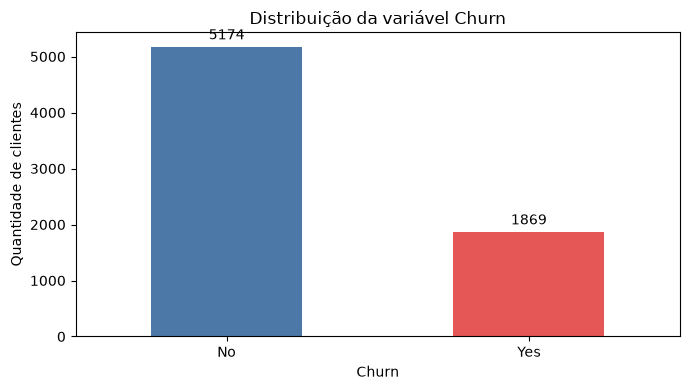

In [25]:
target_counts = df["Churn Label"].value_counts().reindex(["No", "Yes"])

ax = target_counts.plot(
    kind="bar",
    color=["#4C78A8", "#E45756"],
    figsize=(7, 4),
)

ax.set_title("Distribuição da variável Churn")
ax.set_xlabel("Churn")
ax.set_ylabel("Quantidade de clientes")
ax.tick_params(axis="x", rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

### 5.3. Interpretação

A classe `No` reúne **5.174 clientes (73,46%)**, enquanto a classe `Yes` possui **1.869 clientes (26,54%)**. Assim, existe predominância de clientes que não apresentaram churn.

A distribuição é desigual, mas a necessidade de técnicas de balanceamento não deve ser decidida apenas por esses percentuais. Essa decisão deverá considerar o desempenho dos modelos, especialmente na identificação da classe positiva.

Na futura divisão dos dados, será utilizada estratificação para preservar essa proporção nos conjuntos de treino e teste. A avaliação não deverá depender somente de acurácia, pois um modelo que favoreça a classe majoritária pode obter uma acurácia aparentemente alta e ainda detectar poucos clientes com churn. Serão consideradas métricas como:

- precision da classe positiva;
- recall da classe positiva;
- F1-score;
- ROC-AUC e PR-AUC;
- matriz de confusão.

Nenhuma técnica como SMOTE, oversampling ou undersampling será aplicada durante o EDA. Caso necessária, ela será aplicada exclusivamente ao conjunto de treino, evitando vazamento de dados.

### 5.4. Definição preliminar de features e target

In [26]:
columns_to_exclude = (
    [target_column]
    + identifier_columns
    + constant_columns
    + leakage_columns
    + redundant_columns
)

X_preliminary = df.drop(columns=columns_to_exclude)
y = df[target_column].map({"No": 0, "Yes": 1})

print(f"Dimensão preliminar de X: {X_preliminary.shape}")
print(f"Dimensão de y: {y.shape}")
print("Distribuição numérica do target:")
display(y.value_counts().sort_index())

Dimensão preliminar de X: (7043, 24)
Dimensão de y: (7043,)
Distribuição numérica do target:


Churn Label
0    5174
1    1869
Name: count, dtype: int64

A definição acima é **preliminar** e serve para documentar a separação entre features e target. A decisão sobre `CLTV` e sobre quais variáveis geográficas permanecerão será tomada após validação de negócio e continuidade da análise exploratória.